# Algoritmo Genético Simples

**Objetivo:** compreender, passo a passo, a implementação de um Algoritmo Genético (AG) em Python.

No problema de **maximização da função ($f(x)=x^2$)**, cada solução é representada por um cromossomo binário (lista de bits 0 ou 1), que corresponde a um número inteiro ($x$). O objetivo é **encontrar o valor de ($x$) que maximiza a função ($f(x)=x^2$)**.

Considerando um cromossomo de 5 bits, com $(0 \leq x \leq 31)$, a solução ótima é 11111, que representa ($x=31$), com aptidão (fitness) igual a $(f(31)=31^2=961)$.

## 1. Bibliotecas e parâmetros


In [12]:

import random
import matplotlib.pyplot as plt

TAMANHO_POPULACAO = 6
TAMANHO_CROMOSSOMO = 10
NUM_GERACOES = 30
TAXA_CROSSOVER = 0.80
TAXA_MUTACAO = 0.01  # Probabilidade por bit
TAMANHO_TORNEIO = 2

## 2. Criar indivíduos e população

Cada indivíduo é uma lista de inteiros. A população é uma lista de indivíduos.

In [13]:
def gerar_individuo(tamanho):
    return [random.randint(0, 1) for _ in range(tamanho)]


def gerar_populacao(quantidade, tamanho):
    return [gerar_individuo(tamanho) for _ in range(quantidade)]


populacao_exemplo = gerar_populacao(TAMANHO_POPULACAO, TAMANHO_CROMOSSOMO)
for i, individuo in enumerate(populacao_exemplo):
    print(f"Indivíduo {i}: {individuo}")

Indivíduo 0: [1, 0, 1, 1, 0, 0, 0, 0, 1, 0]
Indivíduo 1: [1, 0, 0, 1, 0, 1, 0, 0, 1, 1]
Indivíduo 2: [0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
Indivíduo 3: [1, 1, 1, 1, 1, 1, 0, 0, 0, 1]
Indivíduo 4: [1, 1, 1, 0, 0, 0, 0, 1, 1, 1]
Indivíduo 5: [0, 1, 1, 0, 1, 0, 1, 0, 0, 1]


## 3. Avaliar a aptidão (*fitness*)

A aptidão de um cromossomo é a soma dos seus bits. Exemplo: `101101` tem aptidão 4.

In [14]:
def fitness(individuo):
    return sum(individuo)

exemplo = [1, 0, 1, 1, 0, 1]
print("Indivíduo:", exemplo)
print("Aptidão:", fitness(exemplo))

assert fitness([0, 0, 0]) == 0
assert fitness([1, 1, 1]) == 3

Indivíduo: [1, 0, 1, 1, 0, 1]
Aptidão: 4


## 4. Seleção por torneio

Sorteamos **dois indivíduos distintos** e selecionamos o de maior aptidão. A seleção favorece bons indivíduos, mas não garante que o melhor da população seja escolhido em todo torneio.

In [7]:
def selecao_torneio(populacao, tamanho_torneio=2):
    candidatos = random.sample(populacao, tamanho_torneio)
    vencedor = max(candidatos, key=fitness)
    return vencedor.copy()  # Evita modificar o pai original


pai = selecao_torneio(populacao_exemplo)
print("Pai selecionado:", pai, "| fitness:", fitness(pai))

Pai selecionado: [0, 0, 0, 0, 1, 1, 1, 1, 1, 1] | fitness: 6


## 5. Crossover de um ponto

Com probabilidade de 80%, sorteamos um ponto entre o primeiro e o último bit e trocamos os segmentos finais dos pais. Caso contrário, os filhos são cópias dos pais.

Exemplo: `110|01` e `011|11` produzem `11011` e `01101`.

In [8]:
def crossover(pai1, pai2, taxa_crossover):
    if random.random() < taxa_crossover:
        ponto = random.randint(1, len(pai1) - 1)
        filho1 = pai1[:ponto] + pai2[ponto:]
        filho2 = pai2[:ponto] + pai1[ponto:]
    else:
        ponto = None
        filho1 = pai1.copy()
        filho2 = pai2.copy()
    return filho1, filho2, ponto


pai1 = [1, 1, 0, 0, 1]
pai2 = [0, 1, 1, 1, 1]
filho1, filho2, ponto = crossover(pai1, pai2, 1.0)  # 100% só para demonstrar
print("Pai 1: ", pai1)
print("Pai 2: ", pai2)
print("Ponto: ", ponto)
print("Filho 1:", filho1)
print("Filho 2:", filho2)

Pai 1:  [1, 1, 0, 0, 1]
Pai 2:  [0, 1, 1, 1, 1]
Ponto:  4
Filho 1: [1, 1, 0, 0, 1]
Filho 2: [0, 1, 1, 1, 1]


## 6. Mutação

Para **cada bit**, sorteamos um número aleatório. Se ele for menor que a taxa de mutação, invertemos o bit (`0 → 1` ou `1 → 0`). Uma taxa de 1% **não significa** exatamente uma mutação a cada 100 bits: é uma probabilidade independente por bit.

In [9]:
def mutacao(individuo, taxa_mutacao):
    mutado = individuo.copy()
    for i in range(len(mutado)):
        if random.random() < taxa_mutacao:
            mutado[i] = 1 - mutado[i]
    return mutado


original = [0, 1, 1, 0, 1]
print("Original:             ", original)
print("Mutação a 100% (teste):", mutacao(original, 1.0))
print("Original preservado:  ", original)

Original:              [0, 1, 1, 0, 1]
Mutação a 100% (teste): [1, 0, 0, 1, 0]
Original preservado:   [0, 1, 1, 0, 1]


## 7. Algoritmo Genético completo

A cada geração:

1. Avaliamos a população e registramos o melhor e a média de aptidão.
2. Verificamos o critério de parada.
3. Preservamos uma cópia do melhor indivíduo (**elitismo**).
4. Selecionamos pais, aplicamos crossover e mutação e completamos a próxima população.

O histórico registra também a **população final avaliada**, inclusive quando o limite de gerações é atingido.

In [10]:
def algoritmo_genetico():
    populacao = gerar_populacao(TAMANHO_POPULACAO, TAMANHO_CROMOSSOMO)
    historico_melhor = []
    historico_media = []

    # A geração 0 é a população inicial; a última pode ser NUM_GERACOES.
    for geracao in range(NUM_GERACOES + 1):
        melhor = max(populacao, key=fitness)
        melhor_fitness = fitness(melhor)
        media_fitness = sum(map(fitness, populacao)) / len(populacao)

        historico_melhor.append(melhor_fitness)
        historico_media.append(media_fitness)

        print(f"Geração {geracao:02d} | "
              f"Melhor fitness: {melhor_fitness:2d} | "
              f"Média: {media_fitness:.2f} | "
              f"Melhor indivíduo: {''.join(map(str, melhor))}")

        # Para se encontrou a solução ótima ou atingiu o limite.
        if melhor_fitness == TAMANHO_CROMOSSOMO or geracao == NUM_GERACOES:
            break

        # Elitismo: mantém o melhor indivíduo sem mutação.
        nova_populacao = [melhor.copy()]

        while len(nova_populacao) < TAMANHO_POPULACAO:
            pai1 = selecao_torneio(populacao, TAMANHO_TORNEIO)
            pai2 = selecao_torneio(populacao, TAMANHO_TORNEIO)

            filho1, filho2, _ = crossover(pai1, pai2, TAXA_CROSSOVER)
            filho1 = mutacao(filho1, TAXA_MUTACAO)
            filho2 = mutacao(filho2, TAXA_MUTACAO)

            nova_populacao.append(filho1)
            if len(nova_populacao) < TAMANHO_POPULACAO:
                nova_populacao.append(filho2)

        populacao = nova_populacao

    melhor_final = max(populacao, key=fitness)
    return melhor_final, historico_melhor, historico_media


melhor, historico_melhor, historico_media = algoritmo_genetico()
print("\nMelhor solução encontrada:", melhor)
print("Aptidão final:", fitness(melhor), "/", TAMANHO_CROMOSSOMO)

Geração 00 | Melhor fitness:  6 | Média: 4.33 | Melhor indivíduo: 0011110101
Geração 01 | Melhor fitness:  6 | Média: 4.83 | Melhor indivíduo: 0011110101
Geração 02 | Melhor fitness:  7 | Média: 5.83 | Melhor indivíduo: 0110111101
Geração 03 | Melhor fitness:  7 | Média: 6.33 | Melhor indivíduo: 0110111101
Geração 04 | Melhor fitness:  7 | Média: 6.83 | Melhor indivíduo: 0110111101
Geração 05 | Melhor fitness:  7 | Média: 7.00 | Melhor indivíduo: 0110111101
Geração 06 | Melhor fitness:  7 | Média: 7.00 | Melhor indivíduo: 0110111101
Geração 07 | Melhor fitness:  7 | Média: 7.00 | Melhor indivíduo: 0110111101
Geração 08 | Melhor fitness:  7 | Média: 7.00 | Melhor indivíduo: 0110111101
Geração 09 | Melhor fitness:  7 | Média: 6.83 | Melhor indivíduo: 0110111101
Geração 10 | Melhor fitness:  8 | Média: 7.17 | Melhor indivíduo: 0111111101
Geração 11 | Melhor fitness:  8 | Média: 7.17 | Melhor indivíduo: 0111111101
Geração 12 | Melhor fitness:  8 | Média: 7.33 | Melhor indivíduo: 0111111101


### Atividade: Maximização de uma Função Quadrática com Algoritmo Genético

Considere a função:

$$
f(x) = 100 - (x-10)^2
$$

Sujeita à restrição:

$$
0 \leq x \leq 20, \quad x \in \mathbb{Z}
$$

**Objetivo:** Desenvolver um Algoritmo Genético (AG) capaz de encontrar o valor de $x$ que maximiza a função $f(x)$.

Cada indivíduo da população deverá ser representado por um **cromossomo binário de 5 bits**, correspondente a um valor inteiro de $x$.

O algoritmo deverá contemplar as seguintes etapas:

1. **População inicial:** gerar aleatoriamente cromossomos válidos.
2. **Função fitness:** calcular $f(x)$ para cada indivíduo.
3. **Seleção:** selecionar indivíduos para reprodução.
4. **Cruzamento (crossover):** combinar os cromossomos dos pais.
5. **Mutação:** alterar aleatoriamente bits dos descendentes.
6. **Nova geração:** formar uma nova população e repetir o processo até atingir o critério de parada.

**Resultados esperados:**

- Apresentar o melhor cromossomo encontrado.
- Informar o valor de $x$ e seu respectivo fitness.
- Mostrar a evolução do melhor fitness ao longo das gerações.
- Comparar a solução encontrada com o máximo conhecido da função.


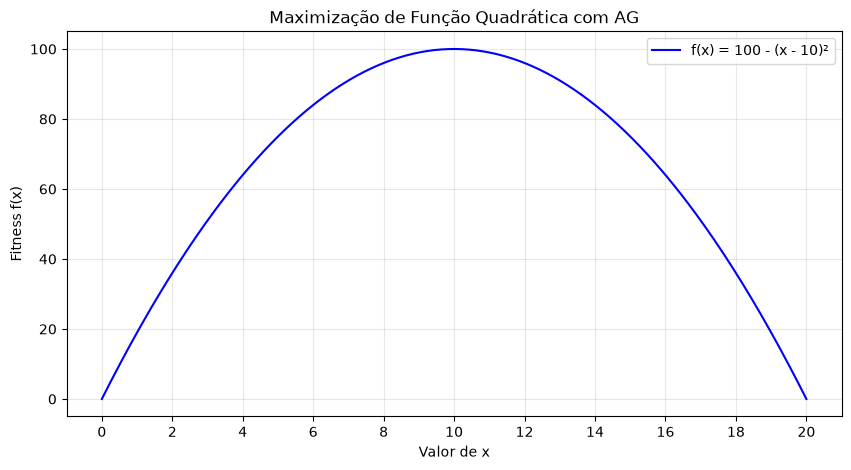

In [11]:

import numpy as np
import matplotlib.pyplot as plt

# Função objetivo (fitness)
def fitness(x):
    return 100 - (x - 10)**2

# Domínio contínuo para desenhar a parábola
x = np.linspace(0, 20, 300)
y = fitness(x)

# Valores inteiros permitidos para o AG
x_inteiros = np.arange(0, 21)
y_inteiros = fitness(x_inteiros)

# Solução ótima conhecida
x_otimo = 10
y_otimo = fitness(x_otimo)

# Construção do gráfico
plt.figure(figsize=(10, 5))

# Curva da função
plt.plot(x, y, color="blue",
         label="f(x) = 100 - (x - 10)²")

# Configurações
plt.title("Maximização de Função Quadrática com AG")
plt.xlabel("Valor de x")
plt.ylabel("Fitness f(x)")
plt.xticks(range(0, 21, 2))
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()
